In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
train = pd.read_csv("/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv")
test = pd.read_csv("/kaggle/input/engage-2-value-from-clicks-to-conversions/test_data.csv")

train_df = train.copy()
test_df = test.copy()

In [3]:
print(train_df.shape)
print(test_df.shape)

(116023, 52)
(29006, 51)


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116023 entries, 0 to 116022
Data columns (total 52 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   trafficSource.isTrueDirect                    42890 non-null   object 
 1   purchaseValue                                 116023 non-null  float64
 2   browser                                       116023 non-null  object 
 3   device.screenResolution                       116023 non-null  object 
 4   trafficSource.adContent                       2963 non-null    object 
 5   trafficSource.keyword                         44162 non-null   object 
 6   screenSize                                    116023 non-null  object 
 7   geoCluster                                    116023 non-null  object 
 8   trafficSource.adwordsClickInfo.slot           4281 non-null    object 
 9   device.mobileDeviceBranding                   11

In [5]:
target_col = 'purchaseValue'
train_df[target_col].describe()

count    1.160230e+05
mean     2.656393e+07
std      2.051825e+08
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.312950e+10
Name: purchaseValue, dtype: float64

The target variable includes high number of Zeroes as you can see the value in 25th, 50th and 75th percentile is zero.

Distribution of Target Variable

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


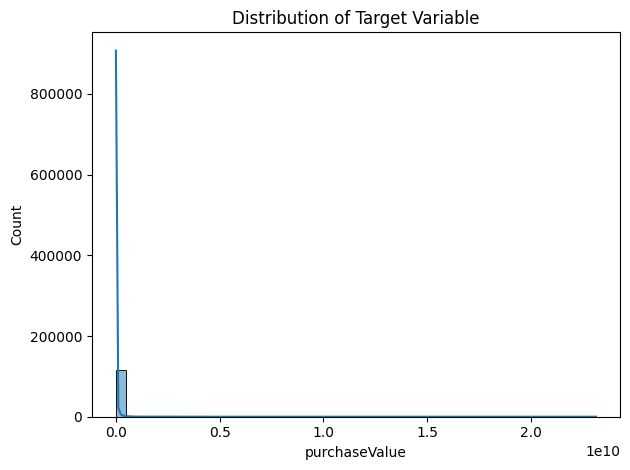

Raw skew:53.90790631995238


In [6]:
sns.histplot(data = train_df, x = target_col, kde = True, bins = 50)
plt.title('Distribution of Target Variable')
plt.tight_layout()
plt.show()
print(f"Raw skew:{train_df[target_col].skew()}")

**The purchaseValue distribution is highly right skewed!!**

In [7]:
cat_cols = train_df.select_dtypes(include = ['object','category']).columns.tolist()
num_cols = train_df.select_dtypes(include = np.number).columns.tolist()
bool_cols = train_df.select_dtypes(include = ['bool']).columns.tolist()
print(f"Number of categorical columns: {len(cat_cols)}")
print(f"Number of numerical columns: {len(num_cols)}")
print(f"Number of boolean columns: {len(bool_cols)}")

Number of categorical columns: 37
Number of numerical columns: 14
Number of boolean columns: 1


# Finding columns with >60% missing value

In [8]:
highly_missing = train_df.isnull().mean().sort_values(ascending = False)
highly_missing = highly_missing[(highly_missing.values) > 0.6]

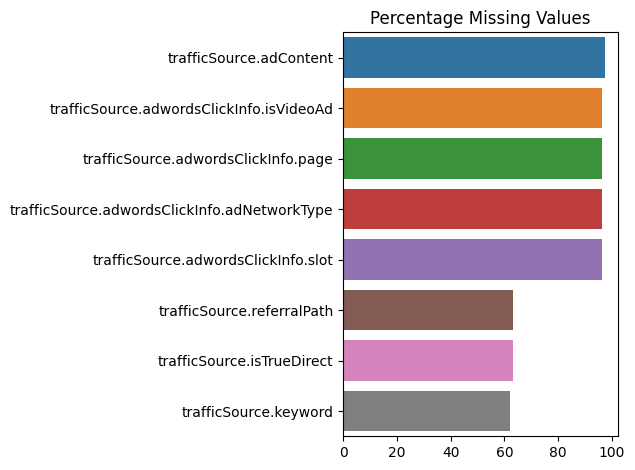

In [9]:
sns.barplot(x = (highly_missing.values)*100, y = highly_missing.index)
plt.title("Percentage Missing Values")
plt.tight_layout()
plt.show()

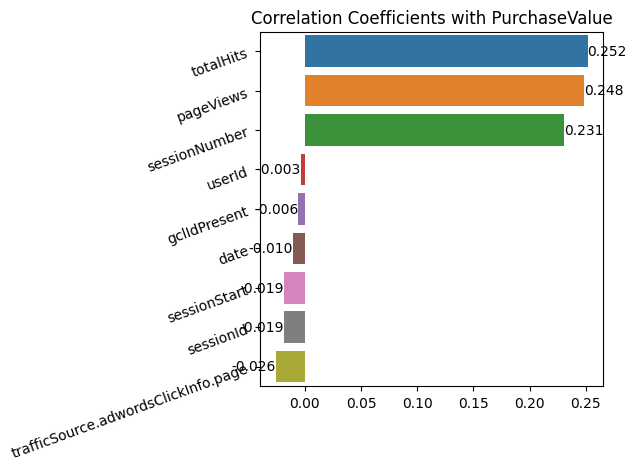

In [10]:
corr = train_df.corr(numeric_only = True)
corr_matrix = corr[target_col].sort_values(ascending = False)[1:10]
ax = sns.barplot(x = corr_matrix.values , y = corr_matrix.index)
for cont in ax.containers:
    ax.bar_label(cont, fmt = '%.3f')
plt.title("Correlation Coefficients with PurchaseValue")
plt.yticks(rotation = 20)
plt.tight_layout()
plt.show()

# Univariate/Bivariate Analysis of TotalHits

In [11]:
train['totalHits'].describe()

count    116023.000000
mean         10.607371
std          19.629576
min           1.000000
25%           1.000000
50%           2.000000
75%          12.000000
max         500.000000
Name: totalHits, dtype: float64

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


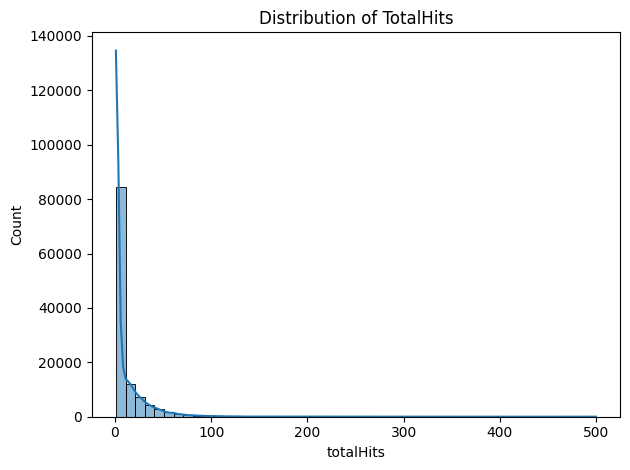

Raw skew:5.601279784107895


In [12]:
sns.histplot(data = train, x = 'totalHits', kde = True, bins = 50)
plt.title("Distribution of TotalHits")
plt.tight_layout()
plt.show()

print(f"Raw skew:{train['totalHits'].skew()}")

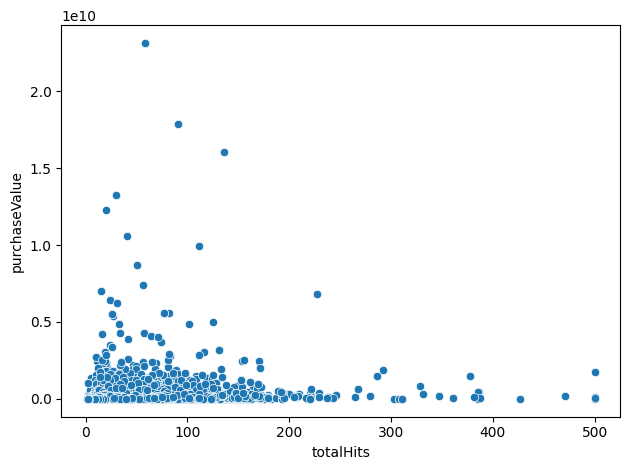

In [13]:
sns.scatterplot(x='totalHits', y=target_col, data=train_df)
plt.tight_layout()
plt.show()

Weak correlation as seen above. Highly skewed distribution again. Needs better FE in order to capture any value from the feature.

In [14]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.preprocessing import PowerTransformer

data = train_df[['totalHits']].copy()

results = {}

results['original'] = data['totalHits'].skew()

results['log1p'] = np.log(data['totalHits']).skew()

results['sqrt'] = np.sqrt(data['totalHits']).skew()

results['cbrt'] = np.cbrt(data['totalHits']).skew()

results['reciprocal'] = (1 / data['totalHits']).skew()

results['square'] = np.square(data['totalHits']).skew()

boxcox_transformed, fit_lambda = stats.boxcox(data['totalHits'])
results['boxcox'] = pd.Series(boxcox_transformed).skew()

pt_yj = PowerTransformer(method='yeo-johnson')
data['yeojohnson'] = pt_yj.fit_transform(data[['totalHits']])
results['yeojohnson'] = data['yeojohnson'].skew()

results = pd.DataFrame.from_dict(results, orient = 'index',columns = ['Skewness']).sort_values(by = 'Skewness', ascending = True)
print(results)

             Skewness
reciprocal   0.115827
boxcox       0.270313
yeojohnson   0.354531
log1p        0.686952
cbrt         1.309070
sqrt         1.797037
original     5.601280
square      42.178206


# Univariate/Bivariate Analysis of PageViews

In [15]:
train['pageViews'].describe()

count    116015.000000
mean          8.412352
std          14.344937
min           1.000000
25%           1.000000
50%           2.000000
75%          10.000000
max         469.000000
Name: pageViews, dtype: float64

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


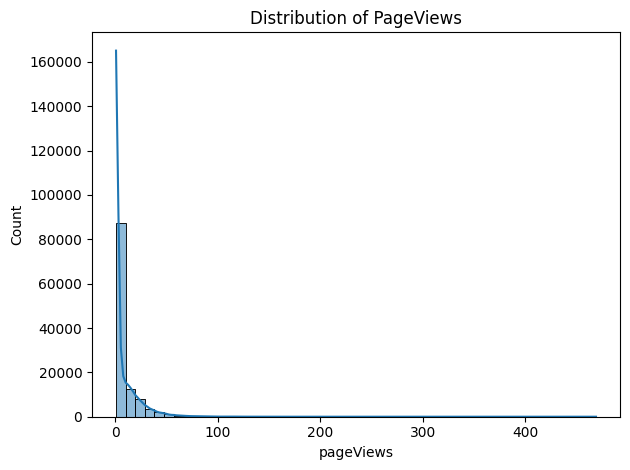

Raw skew:5.601279784107895


In [16]:
sns.histplot(data = train, x = 'pageViews', bins = 50, kde = True)
plt.title('Distribution of PageViews')
plt.tight_layout()
plt.show()

print(f"Raw skew:{train['totalHits'].skew()}")

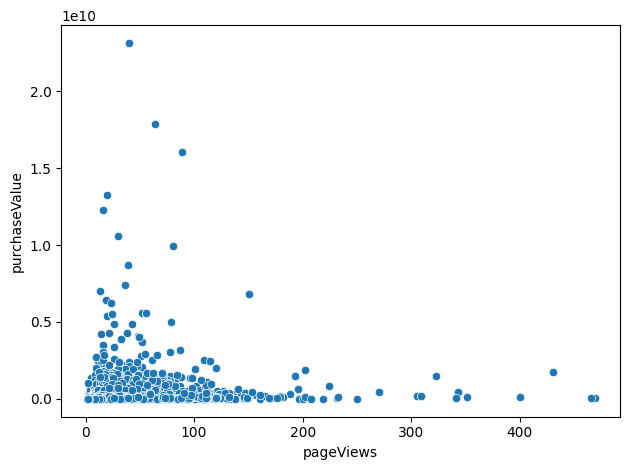

In [17]:
sns.scatterplot(x='pageViews', y=target_col, data=train_df)
plt.tight_layout()
plt.show()

Very similar to plot with totalHits

In [18]:
train_df['pageViews'].isnull().sum()

8

In [19]:
train_df.dropna(subset = ['pageViews'], inplace = True)

In [20]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.preprocessing import PowerTransformer

data = train_df[['pageViews']].copy()

results = {}

results['original'] = data['pageViews'].skew()

results['log1p'] = np.log(data['pageViews']).skew()

results['sqrt'] = np.sqrt(data['pageViews']).skew()

results['cbrt'] = np.cbrt(data['pageViews']).skew()

results['reciprocal'] = (1 / data['pageViews']).skew()

results['square'] = np.square(data['pageViews']).skew()

boxcox_transformed, _lambda = stats.boxcox(data['pageViews'])
results['boxcox'] = pd.Series(boxcox_transformed).skew()

pt_yj = PowerTransformer(method='yeo-johnson')
data['yeojohnson'] = pt_yj.fit_transform(data[['pageViews']])
results['yeojohnson'] = data['yeojohnson'].skew()

results = pd.DataFrame.from_dict(results, orient = 'index',columns = ['Skewness']).sort_values(by = 'Skewness', ascending = True)
print(results)

             Skewness
reciprocal   0.089722
boxcox       0.267260
yeojohnson   0.350829
log1p        0.679177
cbrt         1.247193
sqrt         1.693412
original     5.777727
square      60.523020


# Finding Constant Columns because we will be removing them later

In [21]:
const_cols = [cols for cols in train.columns if train[cols].nunique() == 1]
const_cols

['trafficSource.isTrueDirect',
 'device.screenResolution',
 'screenSize',
 'device.mobileDeviceBranding',
 'device.mobileInputSelector',
 'device.mobileDeviceMarketingName',
 'device.operatingSystemVersion',
 'device.flashVersion',
 'totals.visits',
 'geoNetwork.networkLocation',
 'trafficSource.adwordsClickInfo.isVideoAd',
 'browserMajor',
 'device.browserSize',
 'socialEngagementType',
 'locationZone',
 'device.mobileDeviceModel',
 'totals.bounces',
 'device.language',
 'device.browserVersion',
 'device.screenColors',
 'new_visits']

In [22]:
print(train['totals.bounces'].value_counts())
print(train['new_visits'].value_counts())

totals.bounces
1.0    47148
Name: count, dtype: int64
new_visits
1.0    80518
Name: count, dtype: int64


In [23]:
cols = ['totals.bounces','new_visits']
for col in cols:
  train[col] = train[col].fillna(0).astype(int)
  test[col] = test[col].fillna(0).astype(int)

# FEATURE ENGINEERING

PurchasePerDate = Number of purchases made on a particular day

In [24]:
purchase_counts = (train_df['purchaseValue'] > 0).groupby(train_df['date']).sum()
train_df['PurchasesPerDate'] = train_df['date'].map(purchase_counts).fillna(0).astype(int)
test_df['PurchasesPerDate'] = test_df['date'].map(purchase_counts).fillna(0).astype(int)

PCR = Purchase Conversion rate -> Prob of a purchase being made on a certain date

In [25]:
purchase_counts = (train_df['purchaseValue'] > 0).groupby(train_df['date']).sum()
total_counts = train_df.groupby('date').size()

conversion_rate_per_date = (purchase_counts / total_counts).fillna(0)
train_df['PCR'] = train_df['date'].map(conversion_rate_per_date)
test_df['PCR'] = test_df['date'].map(conversion_rate_per_date).fillna(0)

Engagement Features

In [26]:
train.dropna(subset = ['pageViews'], inplace = True)
test['pageViews'].fillna(test['pageViews'].mean(), inplace = True)

/tmp/ipykernel_100/3184786057.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test['pageViews'].fillna(test['pageViews'].mean(), inplace = True)


In [27]:
train['pageViews_per_hit'] = train['pageViews'] / (train['totalHits'])
test['pageViews_per_hit'] = test['pageViews'] / (test['totalHits'])

train['log_totalHits'] = np.log1p(train['totalHits'])
test['log_totalHits'] = np.log1p(test['totalHits'])

train['log_pageViews'] = np.log1p(train['pageViews'])
test['log_pageViews'] = np.log1p(test['pageViews'])

train['reciprocal_totalHits'] = 1 / (train['totalHits'])
test['reciprocal_totalHits'] = 1 / (test['totalHits'])

train['reciprocal_pageViews'] = 1 / (train['pageViews'])
test['reciprocal_pageViews'] = 1 / (test['pageViews'])

pageviews_bc,_= stats.boxcox(train['pageViews'])
train['pageViews_boxcox'] = pageviews_bc

pageviews_bc_test, _ = stats.boxcox(test['pageViews'])
test['pageViews_boxcox'] = pageviews_bc_test

totalhits_bc, _ = stats.boxcox(train['totalHits'])
train['totalHits_boxcox'] = totalhits_bc

totalhits_bc_test, _ = stats.boxcox(test['totalHits'])
test['totalHits_boxcox'] = totalhits_bc_test

train['PurchasePerDate'] = train_df['PurchasesPerDate']
test['PurchasePerDate'] = test_df['PurchasesPerDate']

train['PCR'] = train_df['PCR']
test['PCR'] = test_df['PCR']

Datetime Features

In [28]:
train['date'] = pd.to_datetime(train['date'], format='%Y%m%d')
train['year'] = train['date'].dt.year
train['month'] = train['date'].dt.month
train['day'] = train['date'].dt.day
train['weekday'] = train['date'].dt.weekday
train['is_weekend'] = (train['date'].dt.weekday >= 5).astype(int)

test['date'] = pd.to_datetime(test['date'], format='%Y%m%d')
test['year'] = test['date'].dt.year
test['month'] = test['date'].dt.month
test['day'] = test['date'].dt.day
test['weekday'] = test['date'].dt.weekday
test['is_weekend'] = (test['date'].dt.weekday >= 5).astype(int)

train.drop(columns = ['date'], inplace =True)
test.drop(columns = ['date'], inplace = True)

UserId aggregate Features

In [29]:
user_totalhits_sum = train_df.groupby('userId')['totalHits'].sum()
train['user_totalhits_sum'] = train['userId'].map(user_totalhits_sum)
user_totalhits_mean = train_df.groupby('userId')['totalHits'].mean()
train['user_totalhits_mean'] = train['userId'].map(user_totalhits_mean)

user_pageviews_sum = train_df.groupby('userId')['pageViews'].sum()
train['user_pageviews_sum'] = train['userId'].map(user_totalhits_sum)
user_pageviews_mean = train_df.groupby('userId')['pageViews'].mean()
train['user_pageviews_mean'] = train['userId'].map(user_totalhits_mean)

train['hits_per_session_number'] = train['totalHits'] / (train['sessionNumber'])
test['hits_per_session_number'] = test['totalHits'] / (test['sessionNumber'])

train['pageviews_per_session_number'] = train['pageViews'] / (train['sessionNumber'])
test['pageviews_per_session_number'] = test['pageViews'] / (test['sessionNumber'])

test['user_totalhits_sum'] = test['userId'].map(user_totalhits_sum).fillna(0)
test['user_totalhits_mean'] = test['userId'].map(user_totalhits_mean).fillna(0)
test['user_pageviews_sum'] = test['userId'].map(user_pageviews_sum).fillna(0)
test['user_pageviews_mean'] = test['userId'].map(user_pageviews_mean).fillna(0)

Categorizing a user based on number of sessions they've had

In [30]:
def get_user_level(session_number):
    if session_number == 1:
        return 'New'
    elif 2 <= session_number <= 5:
        return 'Returning'
    elif 6 <= session_number <= 15:
        return 'Loyal'
    else:
        return 'Max Loyal'

train['user_level'] = train['sessionNumber'].apply(get_user_level)
test['user_level'] = test['sessionNumber'].apply(get_user_level)

# Preprocessing

Dropping columns with high missing values

In [31]:
highly_missing = highly_missing[:8]
train.drop(columns = highly_missing.index, inplace = True)
test.drop(columns = highly_missing.index, inplace = True)

Dropping Constant Columns except totals.bounces and new_visits because they are boolean columns with 0 as missing values. So we will fill the missing values with 0 in these both columns

In [32]:
const_cols = [cols for cols in const_cols if cols not in ['totals.bounces','new_visits','trafficSource.isTrueDirect', 'trafficSource.adwordsClickInfo.isVideoAd']]
train.drop(columns = const_cols, inplace = True)
test.drop(columns = const_cols, inplace = True)

In [33]:
cols = ['totals.bounces', 'new_visits']
for col in cols:
    train[col].fillna(0).astype(int)
    test[col].fillna(0).astype(int)

Finding and processing highly cardinal columns

In [34]:
cat_cols = train.select_dtypes(include = ['object','category'])

In [35]:
cardinal = [cols for cols in cat_cols.columns if train[cols].nunique() > 11]
cardinal

['browser',
 'trafficSource.campaign',
 'geoNetwork.region',
 'trafficSource',
 'os',
 'geoNetwork.subContinent',
 'locationCountry',
 'geoNetwork.city',
 'geoNetwork.metro']

1. Browser

In [36]:
top4 = train['browser'].value_counts()[:4]
train['browser'] = np.where(train['browser'].isin(top4.index), train['browser'], 'Uncommon')
test['browser'] = np.where(test['browser'].isin(top4.index), test['browser'], 'Uncommon')

2. trafficSource.campaign

In [37]:
top6 = train['trafficSource.campaign'].value_counts()[:6]
train['trafficSource.campaign'] = np.where(train['trafficSource.campaign'].isin(top6.index), train['trafficSource.campaign'],'Unknown')
test['trafficSource.campaign'] = np.where(test['trafficSource.campaign'].isin(top6.index), test['trafficSource.campaign'],'Unknown')

3. geoNetwork.region

In [38]:
values = ['not available in demo dataset','(not set)']
train['geoNetwork.region'] = train['geoNetwork.region'].replace(values, 'Missing')
test['geoNetwork.region'] = test['geoNetwork.region'].replace(values, 'Missing')

In [39]:
top10 = train['geoNetwork.region'].value_counts()[:10]
train['geoNetwork.region'] = np.where(train['geoNetwork.region'].isin(top10.index), train['geoNetwork.region'],'Rare')
test['geoNetwork.region'] = np.where(test['geoNetwork.region'].isin(top10.index), test['geoNetwork.region'],'Rare')

4. trafficSource

In [40]:
top3 = train['trafficSource'].value_counts()[:3]
train['trafficSource'] = np.where(train['trafficSource'].isin(top3.index), train['trafficSource'],'Rare')
test['trafficSource'] = np.where(test['trafficSource'].isin(top3.index), test['trafficSource'],'Rare')

5. os

In [41]:
top4_os = train['os'].value_counts()[:4]
train['os'] = np.where(train['os'].isin(top4_os.index), train['os'], 'uc')
test['os'] = np.where(test['os'].isin(top4_os.index), test['os'], 'uc')

6. geoNetwork.subContinent

In [42]:
train['geoNetwork.subContinent'] = train['geoNetwork.subContinent'].apply(lambda x:x if x in ['Northern America', 'Southeast Asia'] else 'Other')
test['geoNetwork.subContinent'] = test['geoNetwork.subContinent'].apply(lambda x:x if x in ['Northern America', 'Southeast Asia'] else 'Other')

7. locationCountry

In [43]:
top5 = train['locationCountry'].value_counts()[:5]
train['locationCountry'] = np.where(train['locationCountry'].isin(top5.index), train['locationCountry'], "OtherCountry")
test['locationCountry'] = np.where(test['locationCountry'].isin(top5.index), test['locationCountry'], "OtherCountry")

8. geoNetwork.city

In [44]:
train['geoNetwork.city'].value_counts()[:5]
values = ['not available in demo dataset','(not set)']
train['geoNetwork.city'] = train['geoNetwork.city'].replace(values, 'MI')
test['geoNetwork.city'] = test['geoNetwork.city'].replace(values, 'MI')

In [45]:
top5_city = train['geoNetwork.city'].value_counts()[:5]
train['geoNetwork.city'] = np.where(train['geoNetwork.city'].isin(top5_city.index), train['geoNetwork.city'], "OtherCity")
test['geoNetwork.city'] = np.where(test['geoNetwork.city'].isin(top5_city.index), test['geoNetwork.city'], "OtherCity")

9. geoNetwork.metro

In [46]:
values = ['not available in demo dataset','(not set)']
train['geoNetwork.metro'] = train['geoNetwork.metro'].replace(values, 'Unavailable')
test['geoNetwork.metro'] = test['geoNetwork.metro'].replace(values, 'Unavailable')

In [47]:
top5_metro = train['geoNetwork.metro'].value_counts()[:5]
train['geoNetwork.metro'] = np.where(train['geoNetwork.metro'].isin(top5_metro.index), train['geoNetwork.metro'], "OtherMetro")
test['geoNetwork.metro'] = np.where(test['geoNetwork.metro'].isin(top5_metro.index), test['geoNetwork.metro'], "OtherMetro")

In [48]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 116015 entries, 0 to 116022
Data columns (total 47 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   purchaseValue                 116015 non-null  float64
 1   browser                       116015 non-null  object 
 2   geoCluster                    116015 non-null  object 
 3   userId                        116015 non-null  int64  
 4   trafficSource.campaign        116015 non-null  object 
 5   geoNetwork.networkDomain      116015 non-null  object 
 6   gclIdPresent                  116015 non-null  int64  
 7   sessionNumber                 116015 non-null  int64  
 8   geoNetwork.region             116015 non-null  object 
 9   trafficSource                 116015 non-null  object 
 10  sessionId                     116015 non-null  int64  
 11  os                            116015 non-null  object 
 12  geoNetwork.subContinent       116015 non-null  ob

In [49]:
train['device.isMobile'] = train['device.isMobile'].astype(int)
test['device.isMobile'] = test['device.isMobile'].astype(int)

Target Encoding userId

In [50]:
train_temp = train.copy()
user_target_mean = train_temp.groupby('userId')['purchaseValue'].mean()
train['user_purchase_mean'] = train['userId'].map(user_target_mean)
test['user_purchase_mean'] = test['userId'].map(user_target_mean).fillna(0)

train.drop(columns=['userId','sessionId','sessionStart'], inplace=True)
test.drop(columns=['userId','sessionId','sessionStart'], inplace=True)

In [51]:
test.isnull().sum()

userChannel                     0
browser                         0
deviceType                      0
device.isMobile                 0
os                              0
geoNetwork.city                 0
geoNetwork.continent            0
locationCountry                 0
geoNetwork.metro                0
geoNetwork.networkDomain        0
geoNetwork.region               0
geoNetwork.subContinent         0
totals.bounces                  0
totalHits                       0
new_visits                      0
pageViews                       0
trafficSource.campaign          0
trafficSource.medium            0
trafficSource                   0
sessionNumber                   0
geoCluster                      0
gclIdPresent                    0
pageViews_per_hit               0
log_totalHits                   0
log_pageViews                   0
reciprocal_totalHits            0
reciprocal_pageViews            0
pageViews_boxcox                0
totalHits_boxcox                0
PurchasePerDat

Final Shape of our dataframes

In [52]:
print(train.shape)
print(test.shape)

(116015, 45)
(29006, 44)


# **Model Training**

In [53]:
X = train.drop(columns=["purchaseValue"])
y = train["purchaseValue"]

In [71]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor,GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import r2_score
from sklearn.linear_model import Ridge, Lasso, LinearRegression

END regressor__colsample_bytree=0.5, regressor__learning_rate=0.02, regressor__max_depth=12, regressor__min_child_weight=1, regressor__n_estimators=1500, regressor__subsample=0.6;, score=0.648 total time=  50.9s

In [88]:
X_reg = X[y>0].copy()
y_reg = y[y>0].copy()

X_train,X_val, y_train, y_val = train_test_split(X_reg, y_reg, test_size = 0.2, random_state = 42)

cat_cols = X_reg.select_dtypes(include = ['object']).columns.tolist()
num_cols = X_reg.select_dtypes(include = np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num",RobustScaler(),num_cols),
    ("cat",OneHotEncoder(handle_unknown = 'ignore'), cat_cols)
], remainder = 'passthrough')

regressor = {
    'Ridge': Ridge(random_state = 42),
    'Lasso': Lasso(random_state = 42, max_iter=10000),
    'LR': LinearRegression(fit_intercept = True, n_jobs = -1),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=15, n_jobs=-1, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
    'GradientBoostingRegressor': GradientBoostingRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, random_state=42),
    'LightGBM': LGBMRegressor(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
    'AdaBoost': AdaBoostRegressor(n_estimators=100, random_state=42),
}

results = {}
for name, regressor in regressor.items():
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', regressor)
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    r2 = r2_score(y_val, y_pred)
    results[name] = r2

top = pd.DataFrame.from_dict(results, orient = 'index', columns = ['r2 Score']).sort_values(by = 'r2 Score', ascending = False)
print(top)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.294e+20, tolerance: 3.319e+17
  model = cd_fast.enet_coordinate_descent(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003790 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3812
[LightGBM] [Info] Number of data points in the train set: 19188, number of used features: 101
[LightGBM] [Info] Start training from score 127581573.299145
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

# **Insights**
1. Tree-based models are performing way better than linear models which basically means that relationship of the features cannot be captured by linear models i.e relationships are non-linear
2. Adaboost assigns more weights to misclassified tuples and hence is very sensitive to outliers and as we know that our purchaseValue has quite some outliers leading to a bad R2 score

# **Hyperparameter Tuning**

In [86]:
from sklearn.model_selection import RandomizedSearchCV

X_reg_hpt = X[y>0].copy()
y_reg_hpt = y[y>0].copy()

X_train_hpt, X_val_hpt, y_train_hpt, y_val_hpt = train_test_split(X_reg_hpt, y_reg_hpt, test_size = 0.2, random_state = 42)

gbr_params = {
    'regressor__n_estimators': [500,800,1100],
    'regressor__learning_rate':[0.01, 0.03, 0.05, 0.07, 0.09],
    'regressor__max_depth': [6,7,8,9],
    'regressor__subsample': [0.5, 0.7, 0.9],
    'regressor__min_samples_leaf': [1,2]
}

xgb_params = {
    'regressor__n_estimators': [1200,1500,1800],
    'regressor__learning_rate':[0.02, 0.04, 0.06, 0.08, 0.1, 0.12],
    'regressor__max_depth': [7,8,9,10,11,12],
    'regressor__subsample': [0.4,0.5,0.6,0.8],
    'regressor__min_child_weight': [1,2,5],
    'regressor__colsample_bytree': [0.3,0.5,0.7]
}

rf_params = {
    'regressor__n_estimators': [400, 600, 700],
    'regressor__max_depth': [8, 15, 25, None],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 4]
}

gbr = GradientBoostingRegressor(random_state = 42)
xgb = XGBRegressor(random_state = 42, n_jobs = -1)
rf = RandomForestRegressor(random_state = 42, n_jobs = -1)

tuner = {
    "GBR": (gbr, gbr_params),
    "XGB": (xgb, xgb_params),
    "RF": (rf, rf_params)
}

results = {}

for name, (model,params) in tuner.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    print(f"Tuning {name}")
    
    search = RandomizedSearchCV(pipeline, param_distributions = params, n_iter = 25, scoring = 'r2', n_jobs = -1, verbose = 3, random_state = 42, cv= 2)
    search.fit(X_train_hpt, y_train_hpt)
    print(f"Best params for {name} : {search.best_params_}")

    best_model = search.best_estimator_
    y_pred_hpt = best_model.predict(X_val_hpt)
    score = r2_score(y_val_hpt, y_pred_hpt)
    results[name] = score
    print(f"Tuned {name} R² Score: {score:.4f}\n")

final = pd.DataFrame.from_dict(results, orient = 'index', columns = ['R2 score']).sort_values(by = 'R2 score', ascending = False)
print(final)    

Tuning GBR
Fitting 2 folds for each of 25 candidates, totalling 50 fits
[CV 1/2] END regressor__learning_rate=0.01, regressor__max_depth=8, regressor__min_samples_leaf=1, regressor__n_estimators=1100, regressor__subsample=0.5;, score=0.520 total time= 2.0min
[CV 2/2] END regressor__learning_rate=0.01, regressor__max_depth=8, regressor__min_samples_leaf=1, regressor__n_estimators=1100, regressor__subsample=0.5;, score=0.550 total time= 2.1min
[CV 2/2] END regressor__learning_rate=0.07, regressor__max_depth=6, regressor__min_samples_leaf=1, regressor__n_estimators=1100, regressor__subsample=0.9;, score=0.352 total time= 2.8min
[CV 1/2] END regressor__learning_rate=0.07, regressor__max_depth=6, regressor__min_samples_leaf=1, regressor__n_estimators=1100, regressor__subsample=0.9;, score=0.371 total time= 2.9min
[CV 1/2] END regressor__learning_rate=0.07, regressor__max_depth=9, regressor__min_samples_leaf=2, regressor__n_estimators=1100, regressor__subsample=0.5;, score=0.419 total time= 

/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV 2/2] END regressor__colsample_bytree=0.5, regressor__learning_rate=0.08, regressor__max_depth=12, regressor__min_child_weight=1, regressor__n_estimators=1800, regressor__subsample=0.8;, score=0.583 total time= 1.3min
[CV 1/2] END regressor__colsample_bytree=0.7, regressor__learning_rate=0.06, regressor__max_depth=11, regressor__min_child_weight=1, regressor__n_estimators=1200, regressor__subsample=0.8;, score=0.507 total time= 1.1min
[CV 1/2] END regressor__colsample_bytree=0.7, regressor__learning_rate=0.04, regressor__max_depth=10, regressor__min_child_weight=1, regressor__n_estimators=1200, regressor__subsample=0.8;, score=0.510 total time=  39.9s
[CV 2/2] END regressor__colsample_bytree=0.7, regressor__learning_rate=0.06, regressor__max_depth=11, regressor__min_child_weight=1, regressor__n_estimators=1200, regressor__subsample=0.8;, score=0.539 total time= 1.1min
[CV 2/2] END regressor__colsample_bytree=0.7, regressor__learning_rate=0.04, regressor__max_depth=10, regressor__min

/usr/local/lib/python3.11/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV 1/2] END regressor__max_depth=8, regressor__min_samples_leaf=1, regressor__min_samples_split=2, regressor__n_estimators=400;, score=0.456 total time= 1.0min
[CV 2/2] END regressor__max_depth=8, regressor__min_samples_leaf=1, regressor__min_samples_split=2, regressor__n_estimators=400;, score=0.497 total time= 1.0min
[CV 1/2] END regressor__max_depth=25, regressor__min_samples_leaf=4, regressor__min_samples_split=10, regressor__n_estimators=600;, score=0.547 total time= 2.8min
[CV 2/2] END regressor__max_depth=25, regressor__min_samples_leaf=4, regressor__min_samples_split=10, regressor__n_estimators=600;, score=0.543 total time= 2.8min
[CV 1/2] END regressor__max_depth=8, regressor__min_samples_leaf=4, regressor__min_samples_split=2, regressor__n_estimators=400;, score=0.551 total time= 1.0min
[CV 2/2] END regressor__max_depth=8, regressor__min_samples_leaf=4, regressor__min_samples_split=2, regressor__n_estimators=400;, score=0.546 total time= 1.0min
[CV 1/2] END regressor__max_de

XGB overtakes GBR as our top performer. Randomforest performs poorer than expected. XGBoost as name suggest Extreme Gradient Boosting is also better suited because of our dataset size and its core performance. It is faster than all other regressors and provides a better generalization than other models.

# **Submissions**

**1. For XGB**

In [94]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("XGB", XGBRegressor(subsample = 0.5, n_estimators= 1800, min_child_weight= 1, max_depth= 7, learning_rate= 0.1, colsample_bytree = 0.5))
])

xgb_pipeline.fit(X,y)
xgb_preds = xgb_pipeline.predict(test)
xgb_preds = np.maximum(xgb_preds, 0)

submission = pd.DataFrame({
    "id": np.arange(len(test)),
    "purchaseValue": xgb_preds
})

submission.to_csv("xgb.csv", index = False)

**2. For GBR**

In [ ]:
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("GBR", GradientBoostingRegressor(regressor__subsample =  0.5, n_estimators = 500, min_samples_leaf = 1, regressor__max_depth = 9,
                                      learning_rate = 0.03))
])

gb_pipeline.fit(X,y)
gb_preds = gb_pipeline.predict(test)
gb_preds = np.maximum(gb_preds, 0)

submission = pd.DataFrame({
    "id": np.arange(len(test)),
    "purchaseValue": gb_preds
})

submission.to_csv("gbr.csv", index = False)

**3. For RandomForest**

In [ ]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("RFR", RandomForestRegressor(regressor__n_estimators = 400, min_samples_split = 2, min_samples_leaf = 4, max_depth = 15)
])

rf_pipeline.fit(X,y)
rf_preds = rf_pipeline.predict(test)
rf_preds = np.maximum(rf_preds, 0)

submission = pd.DataFrame({
    "id": np.arange(len(test)),
    "purchaseValue": rf_preds
})

submission.to_csv("rf.csv", index = False)